In [1]:
from google.colab import drive

drive.mount('/content/drive')
path = '/content/drive/MyDrive/Datasheet/movies_metadata.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd

df = pd.read_csv(path)
df.info()

/tmp/ipykernel_41015/3766738840.py:3: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45466 non-null  object 
 3   genres                 45466 non-null  object 
 4   homepage               7782 non-null   object 
 5   id                     45466 non-null  object 
 6   imdb_id                45449 non-null  object 
 7   original_language      45455 non-null  object 
 8   original_title         45466 non-null  object 
 9   overview               44512 non-null  object 
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  object 
 12  production_companies   45463 non-null  object 
 13  production_countries   45463 non-null  object 
 14  release_date           45379 non-null  object 
 15  re

In [3]:
df['popularity'].isna().sum()

np.int64(5)

In [4]:
df['popularity'].value_counts()

,count
popularity,
0.0,34
0.0,32
1e-06,30
0.000844,26
0.000001,26
...,...
1.806613,1
3.553427,1
4.496482,1


In [5]:
df.describe()

,revenue,runtime,vote_average,vote_count
count,4.546000e+04,45203.000000,45460.000000,45460.000000
mean,1.120935e+07,94.128199,5.618207,109.897338
std,6.433225e+07,38.407810,1.924216,491.310374
min,0.000000e+00,0.000000,0.000000,0.000000
25%,0.000000e+00,85.000000,5.000000,3.000000
50%,0.000000e+00,95.000000,6.000000,10.000000
75%,0.000000e+00,107.000000,6.800000,34.000000
max,2.787965e+09,1256.000000,10.000000,14075.000000


In [6]:
df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce')

In [7]:
# Jumlah nilai popularity bernilai negatif
print('Jumlah nilai popularity bernilai negatif',(df['popularity']<=0).sum())

Jumlah nilai popularity bernilai negatif 66


In [8]:
df.columns

Index(['adult', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id',
       'imdb_id', 'original_language', 'original_title', 'overview',
       'popularity', 'poster_path', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title', 'video',
       'vote_average', 'vote_count'],
      dtype='object')

**Data Cleaning**

In [9]:
Feature = ['genres','belongs_to_collection','budget','production_companies','production_countries']
df = df[Feature]

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   genres                 45466 non-null  object
 1   belongs_to_collection  4494 non-null   object
 2   budget                 45466 non-null  object
 3   production_companies   45463 non-null  object
 4   production_countries   45463 non-null  object
dtypes: object(5)
memory usage: 1.7+ MB


In [11]:
df.isna().sum()

,0
genres,0
belongs_to_collection,40972
budget,0
production_companies,3
production_countries,3


In [12]:
df.head(5)

,genres,belongs_to_collection,budget,production_companies,production_countries
0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...","{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o..."
1,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,65000000,"[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o..."
2,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...","{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o..."
3,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,16000000,[{'name': 'Twentieth Century Fox Film Corporat...,"[{'iso_3166_1': 'US', 'name': 'United States o..."
4,"[{'id': 35, 'name': 'Comedy'}]","{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'name': 'Sandollar Productions', 'id': 5842}...","[{'iso_3166_1': 'US', 'name': 'United States o..."


In [13]:
import ast

def get_extraction_name(x):
  if isinstance(x, float):
    return ""

  try:
    data_list = ast.literal_eval(x)
    return [item['name']for item in data_list]
  except (ValueError, SyntaxError, TypeError,KeyError):
    return ""

In [14]:
def get_colletion_name(x):
  if isinstance(x, float):
    return ""

  try:
    data_collection = ast.literal_eval(x)
    return data_collection['name']
  except (ValueError, SyntaxError, TypeError, KeyError):
    return ""

In [15]:
kolom_semistructured = ['genres','production_companies','production_countries']
for col in kolom_semistructured:
  df[col] = df[col].apply(get_extraction_name)

In [16]:
df['belongs_to_collection'] = df['belongs_to_collection'].apply(get_colletion_name)

In [17]:
df.head()

,genres,belongs_to_collection,budget,production_companies,production_countries
0,"[Animation, Comedy, Family]",Toy Story Collection,30000000,[Pixar Animation Studios],[United States of America]
1,"[Adventure, Fantasy, Family]",,65000000,"[TriStar Pictures, Teitler Film, Interscope Co...",[United States of America]
2,"[Romance, Comedy]",Grumpy Old Men Collection,0,"[Warner Bros., Lancaster Gate]",[United States of America]
3,"[Comedy, Drama, Romance]",,16000000,[Twentieth Century Fox Film Corporation],[United States of America]
4,[Comedy],Father of the Bride Collection,0,"[Sandollar Productions, Touchstone Pictures]",[United States of America]


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   genres                 45466 non-null  object
 1   belongs_to_collection  45466 non-null  object
 2   budget                 45466 non-null  object
 3   production_companies   45466 non-null  object
 4   production_countries   45466 non-null  object
dtypes: object(5)
memory usage: 1.7+ MB


In [19]:
df['budget'] = pd.to_numeric(df['budget'], errors='coerce')

In [20]:
df.isna().sum()

,0
genres,0
belongs_to_collection,0
budget,3
production_companies,0
production_countries,0


In [21]:
missing_budget = df['budget'].isna()
display(df[missing_budget][['belongs_to_collection','genres','production_companies','production_countries','budget']])

,belongs_to_collection,genres,production_companies,production_countries,budget
19730,,"[Carousel Productions, Vision View Entertainme...",,,NaN
29503,,"[Aniplex, GoHands, BROSTA TV, Mardock Scramble...",,,NaN
35587,,"[Odyssey Media, Pulser Productions, Rogue Stat...",,,NaN


In [22]:
df['budget'].value_counts()

,count
budget,
0.0,36573
5000000.0,286
10000000.0,259
20000000.0,243
2000000.0,242
...,...
152000000.0,1
1500.0,1
82000.0,1


In [23]:
df.dropna(subset=['budget'], inplace=True)

In [24]:
df.isna().sum()

,0
genres,0
belongs_to_collection,0
budget,0
production_companies,0
production_countries,0


In [25]:
GENRE_RESMI = {
    'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
    'Documentary', 'Drama', 'Family', 'Fantasy', 'History',
    'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction',
    'TV Movie', 'Thriller', 'War', 'Western', 'Foreign'
}

In [26]:
anomali_genres = df['genres'].explode()

In [27]:
anomali_genres.value_counts()

,count
genres,
Drama,20265
Comedy,13182
Thriller,7624
Romance,6735
Action,6596
Horror,4673
Crime,4307
Documentary,3932
Adventure,3496


In [28]:
anomali_ditemukan = anomali_genres[~anomali_genres.isin(GENRE_RESMI)]
display(anomali_ditemukan.value_counts())

,count
genres,


In [29]:
df['genres'] = df['genres'].apply(lambda lst: [g for g in lst if g in GENRE_RESMI]if isinstance(lst,list)else[])

In [30]:
anomali_companies = df['production_companies'].explode()
display(anomali_companies.value_counts())

,count
production_companies,
Warner Bros.,1250
Metro-Goldwyn-Mayer (MGM),1076
Paramount Pictures,1003
Twentieth Century Fox Film Corporation,836
Universal Pictures,830
...,...
Bossa Nova Productions,1
Flood Productions,1
Taska Productions,1


In [31]:
anomali_countries = df['production_countries'].explode()
display(anomali_countries.value_counts())

,count
production_countries,
United States of America,21153
United Kingdom,4094
France,3940
Germany,2254
Italy,2169
...,...
Antarctica,1
Gibraltar,1
Brunei Darussalam,1


In [32]:
df.head()

,genres,belongs_to_collection,budget,production_companies,production_countries
0,"[Animation, Comedy, Family]",Toy Story Collection,30000000.0,[Pixar Animation Studios],[United States of America]
1,"[Adventure, Fantasy, Family]",,65000000.0,"[TriStar Pictures, Teitler Film, Interscope Co...",[United States of America]
2,"[Romance, Comedy]",Grumpy Old Men Collection,0.0,"[Warner Bros., Lancaster Gate]",[United States of America]
3,"[Comedy, Drama, Romance]",,16000000.0,[Twentieth Century Fox Film Corporation],[United States of America]
4,[Comedy],Father of the Bride Collection,0.0,"[Sandollar Productions, Touchstone Pictures]",[United States of America]


In [33]:
def get_studio_name(companies_list):
  if isinstance(companies_list, list) and len(companies_list) > 0:
    return companies_list[0]
  return 'Other_Company'

In [34]:
def get_country_name(countries_list):
  if isinstance(countries_list, list) and len(countries_list) > 0:
    return countries_list[0]
  return 'Other_Countries'

In [35]:
df['lead_company'] = df['production_companies'].apply(get_studio_name)
df['lead_country'] = df['production_countries'].apply(get_country_name)

In [36]:
df.head()

,genres,belongs_to_collection,budget,production_companies,production_countries,lead_company,lead_country
0,"[Animation, Comedy, Family]",Toy Story Collection,30000000.0,[Pixar Animation Studios],[United States of America],Pixar Animation Studios,United States of America
1,"[Adventure, Fantasy, Family]",,65000000.0,"[TriStar Pictures, Teitler Film, Interscope Co...",[United States of America],TriStar Pictures,United States of America
2,"[Romance, Comedy]",Grumpy Old Men Collection,0.0,"[Warner Bros., Lancaster Gate]",[United States of America],Warner Bros.,United States of America
3,"[Comedy, Drama, Romance]",,16000000.0,[Twentieth Century Fox Film Corporation],[United States of America],Twentieth Century Fox Film Corporation,United States of America
4,[Comedy],Father of the Bride Collection,0.0,"[Sandollar Productions, Touchstone Pictures]",[United States of America],Sandollar Productions,United States of America


**Preprocessing**

In [37]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
genres_encoded = mlb.fit_transform(df['genres'])
genre_encoded = pd.DataFrame(genres_encoded, columns=mlb.classes_, index=df.index)
df = pd.concat([df, genre_encoded], axis = 1)

In [38]:
# Ambil top 10 perusahaan production
top_10_production = df['lead_company'].value_counts().head(10).index
df['production_clean'] = df['lead_company'].apply(lambda x: x if x in top_10_production else 'Other_Company')

In [39]:
# Ambil top 10 country
top_10_country = df['lead_country'].value_counts().head(10).index
df['country_clean'] = df['lead_country'].apply(lambda x: x if x in top_10_country else 'Othe_Countries')

In [40]:
df['belongs_to_collection'].value_counts()

,count
belongs_to_collection,
,40972
The Bowery Boys,29
Totò Collection,27
James Bond Collection,26
Zatôichi: The Blind Swordsman,26
...,...
Чебурашка и крокодил Гена,1
Tomtar och Trolltyg Collection,1
Hailey Dean Mystery Collection,1


In [41]:
df['belongs_to_collection'] = df['belongs_to_collection'].apply(lambda x: 1 if pd.notna(x) and str(x).strip() !='' else 0)

In [42]:
df['belongs_to_collection'].value_counts()

,count
belongs_to_collection,
0,40972
1,4491


In [43]:
df.head()

,genres,belongs_to_collection,budget,production_companies,production_countries,lead_company,lead_country,Action,Adventure,Animation,...,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western,production_clean,country_clean
0,"[Animation, Comedy, Family]",1,30000000.0,[Pixar Animation Studios],[United States of America],Pixar Animation Studios,United States of America,0,0,1,...,0,0,0,0,0,0,0,0,Other_Company,United States of America
1,"[Adventure, Fantasy, Family]",0,65000000.0,"[TriStar Pictures, Teitler Film, Interscope Co...",[United States of America],TriStar Pictures,United States of America,0,1,0,...,0,0,0,0,0,0,0,0,Other_Company,United States of America
2,"[Romance, Comedy]",1,0.0,"[Warner Bros., Lancaster Gate]",[United States of America],Warner Bros.,United States of America,0,0,0,...,0,0,1,0,0,0,0,0,Warner Bros.,United States of America
3,"[Comedy, Drama, Romance]",0,16000000.0,[Twentieth Century Fox Film Corporation],[United States of America],Twentieth Century Fox Film Corporation,United States of America,0,0,0,...,0,0,1,0,0,0,0,0,Twentieth Century Fox Film Corporation,United States of America
4,[Comedy],1,0.0,"[Sandollar Productions, Touchstone Pictures]",[United States of America],Sandollar Productions,United States of America,0,0,0,...,0,0,0,0,0,0,0,0,Other_Company,United States of America


In [44]:
df.describe()

,belongs_to_collection,budget,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
count,45463.000000,4.546300e+04,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,...,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000
mean,0.098784,4.224579e+06,0.145085,0.076898,0.042562,0.289950,0.094736,0.086488,0.445747,0.060929,...,0.030750,0.102787,0.035149,0.054264,0.148142,0.067066,0.016871,0.167697,0.029101,0.022920
std,0.298375,1.742413e+07,0.352190,0.266432,0.201870,0.453744,0.292854,0.281086,0.497053,0.239202,...,0.172642,0.303684,0.184160,0.226540,0.355245,0.250138,0.128789,0.373601,0.168090,0.149649
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000e+00,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,3.800000e+08,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [45]:
# Cek skew sebelum ditransofmrasi
print('Skew pada budget',df['budget'].skew())

Skew pada budget 7.125325958544954


In [46]:
# Mengatasi Skewnees vote_count(quartil ketiga ke max sangat jauh) dan vote_average
import numpy as np

df['budget'] = np.log1p(df['budget'])

In [47]:
# Cek skew setelah transformasi
print('Skew pada budget',df['budget'].skew())

Skew pada budget 1.6373864105219045


In [55]:
columns_todrop = ['genres','production_companies','production_countries','lead_company','lead_country']

In [56]:
X = df.drop(columns=columns_todrop)

In [57]:
X.head()

,belongs_to_collection,budget,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,...,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western,production_clean,country_clean
0,1,17.216708,0,0,1,1,0,0,0,1,...,0,0,0,0,0,0,0,0,Other_Company,United States of America
1,0,17.989898,0,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,Other_Company,United States of America
2,1,0.000000,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,Warner Bros.,United States of America
3,0,16.588099,0,0,0,1,0,0,1,0,...,0,0,1,0,0,0,0,0,Twentieth Century Fox Film Corporation,United States of America
4,1,0.000000,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,Other_Company,United States of America


In [58]:
X.describe()

,belongs_to_collection,budget,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
count,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,...,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000,45463.000000
mean,0.098784,3.005372,0.145085,0.076898,0.042562,0.289950,0.094736,0.086488,0.445747,0.060929,...,0.030750,0.102787,0.035149,0.054264,0.148142,0.067066,0.016871,0.167697,0.029101,0.022920
std,0.298375,6.217945,0.352190,0.266432,0.201870,0.453744,0.292854,0.281086,0.497053,0.239202,...,0.172642,0.303684,0.184160,0.226540,0.355245,0.250138,0.128789,0.373601,0.168090,0.149649
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,19.755682,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [61]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45463 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   belongs_to_collection  45463 non-null  int64  
 1   budget                 45463 non-null  float64
 2   Action                 45463 non-null  int64  
 3   Adventure              45463 non-null  int64  
 4   Animation              45463 non-null  int64  
 5   Comedy                 45463 non-null  int64  
 6   Crime                  45463 non-null  int64  
 7   Documentary            45463 non-null  int64  
 8   Drama                  45463 non-null  int64  
 9   Family                 45463 non-null  int64  
 10  Fantasy                45463 non-null  int64  
 11  Foreign                45463 non-null  int64  
 12  History                45463 non-null  int64  
 13  Horror                 45463 non-null  int64  
 14  Music                  45463 non-null  int64  
 15  Mystery

In [59]:
X.columns

Index(['belongs_to_collection', 'budget', 'Action', 'Adventure', 'Animation',
       'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy',
       'Foreign', 'History', 'Horror', 'Music', 'Mystery', 'Romance',
       'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western',
       'production_clean', 'country_clean'],
      dtype='object')

In [62]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
num_feat = ['budget']
num_transform = scaler

In [63]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore',sparse_output=False)
cat_feat = ['production_clean','country_clean']
cat_transform = encoder

In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer([
    ('num', num_transform, num_feat),
    ('cat', cat_transform, cat_feat)
])

**Kmeans**

In [76]:
# Menguji n_cluster dengan metode silhouette score
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

X_preprocessed = preprocessor.fit_transform(X)

In [98]:
k_range = range(2,10)
silhouette_scores = []
print("Hasil Evaluasi Silhouette Score")
for k in k_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  cluster_labels = kmeans.fit_predict(X_preprocessed)
  score = silhouette_score(X_preprocessed, cluster_labels)
  silhouette_scores.append(score)
  print(f"Jumlah Cluster (K = {k}) : {score:.4f}")

Hasil Evaluasi Silhouette Score
Jumlah Cluster (K = 2) : 0.5501
Jumlah Cluster (K = 3) : 0.4083
Jumlah Cluster (K = 4) : 0.4574
Jumlah Cluster (K = 5) : 0.5823
Jumlah Cluster (K = 6) : 0.6220
Jumlah Cluster (K = 7) : 0.6664
Jumlah Cluster (K = 8) : 0.6435
Jumlah Cluster (K = 9) : 0.6850


In [99]:
best_k = k_range[silhouette_scores.index(max(silhouette_scores))]
print(f"\nRekomendasi cluster terbaik berdasrkan silhouette score: K= {best_k}")


Rekomendasi cluster terbaik berdasrkan silhouette score: K= 9


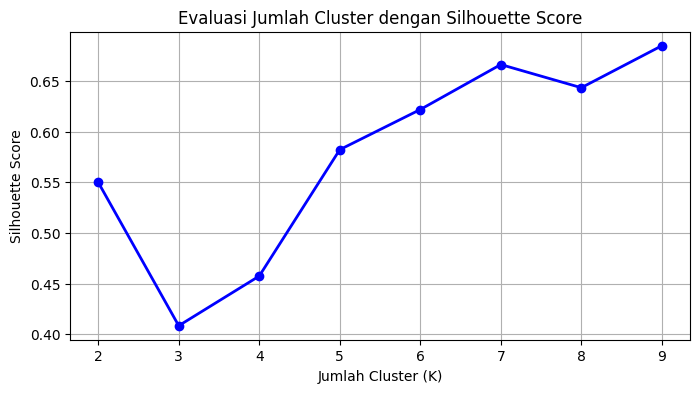

In [100]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.plot(k_range, silhouette_scores, marker='o', linewidth=2, color='b')
plt.title('Evaluasi Jumlah Cluster dengan Silhouette Score')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

In [101]:
kmeans = KMeans(n_clusters=6 ,random_state=42,n_init=10)

In [102]:
kmeans_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model',kmeans)
])

In [103]:
cluster_labels = kmeans_pipeline.fit_predict(X)

In [104]:
df['cluster'] = cluster_labels

In [105]:
X_preprocessed = kmeans_pipeline.named_steps['preprocessor'].transform(X)

In [106]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

sil_score = silhouette_score(X_preprocessed, cluster_labels)
ch_score = calinski_harabasz_score(X_preprocessed, cluster_labels)
db_score = davies_bouldin_score(X_preprocessed, cluster_labels)

print("Evaluasi Model KMeans")
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Calinski-Harabasz Score: {ch_score:.4f}")
print(f"Davies-Bouldin Score: {db_score:.4f}")

Evaluasi Model KMeans
Silhouette Score: 0.6220
Calinski-Harabasz Score: 27617.1446
Davies-Bouldin Score: 0.9895


In [108]:
cluster_summary = df.groupby('cluster').agg(
    Jumlah_Film = ('budget','count'),
    Budget_Mean = ('budget', 'mean'),
    Budget_Median = ('budget', 'median'),
    Collection_ratio = ('belongs_to_collection', lambda x: (x == 1).mean())
).reset_index()

In [109]:
print('==== Cluster Summary K=6 =====')
print(cluster_summary)

==== Cluster Summary K=6 =====
   cluster  Jumlah_Film  Budget_Mean  Budget_Median  Collection_ratio
0        0        10931     0.016184       0.000000          0.098436
1        1         8602    15.736601      16.012735          0.182864
2        2         3445     0.034024       0.000000          0.067344
3        3         6355     0.049021       0.000000          0.071125
4        4         6043     0.041456       0.000000          0.039384
5        5        10087     0.040729       0.000000          0.091207


In [111]:
genre_cols = [c for c in df.columns if c in GENRE_RESMI]
if genre_cols:
  print('==== Top Genre Per Cluster ====')
  top_genres = df.groupby('cluster')[genre_cols].mean()
  display(top_genres.style.highlight_max(axis=1, color='lightgreen'))

==== Top Genre Per Cluster ====


,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,Fantasy,Foreign,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
cluster,,,,,,,,,,,,,,,,,,,,
0,0.122679,0.069436,0.058915,0.284512,0.090385,0.065227,0.503614,0.044003,0.060653,0.059189,0.040893,0.098802,0.023511,0.055896,0.145732,0.062940,0.015735,0.146281,0.035404,0.014637
1,0.241688,0.146594,0.048128,0.314578,0.143455,0.024762,0.469774,0.082423,0.083353,0.012555,0.043246,0.142292,0.034062,0.073471,0.166822,0.114973,0.004534,0.272262,0.035922,0.015927
2,0.129753,0.083019,0.021480,0.384906,0.139623,0.005225,0.513498,0.056604,0.031060,0.001161,0.026996,0.042380,0.086502,0.080697,0.287954,0.033672,0.000290,0.131495,0.053991,0.091437
3,0.139418,0.055075,0.023918,0.273800,0.083871,0.069079,0.555153,0.039182,0.040913,0.088277,0.033832,0.079937,0.019512,0.044060,0.135169,0.035877,0.002990,0.150275,0.029898,0.008655
4,0.066854,0.027801,0.031441,0.194109,0.032434,0.207513,0.262121,0.051134,0.022009,0.044514,0.015555,0.051630,0.038061,0.022340,0.091014,0.034089,0.025484,0.078438,0.011749,0.008936
5,0.142659,0.066620,0.045702,0.310003,0.086745,0.128383,0.380490,0.081987,0.042927,0.003272,0.017547,0.139090,0.039258,0.052642,0.129474,0.081491,0.037871,0.178547,0.017845,0.031823


In [112]:
cluster_names = {
    0: "General Mainstream (Mid-To-Low)",
    1: "Studio Blockbuster & Mainstream Commercial",
    2: "Indie Romance & Drama",
    3: "Foreign & Niche International",
    4: "Documentary & Non-Fiction",
    5: "Genre Hybrid (Horror/Action/Comedy)"
}

In [113]:
df['cluster_profile'] = df['cluster'].map(cluster_names)
display(df['cluster_profile'].value_counts())

,count
cluster_profile,
General Mainstream (Mid-To-Low),10931
Genre Hybrid (Horror/Action/Comedy),10087
Studio Blockbuster & Mainstream Commercial,8602
Foreign & Niche International,6355
Documentary & Non-Fiction,6043
Indie Romance & Drama,3445


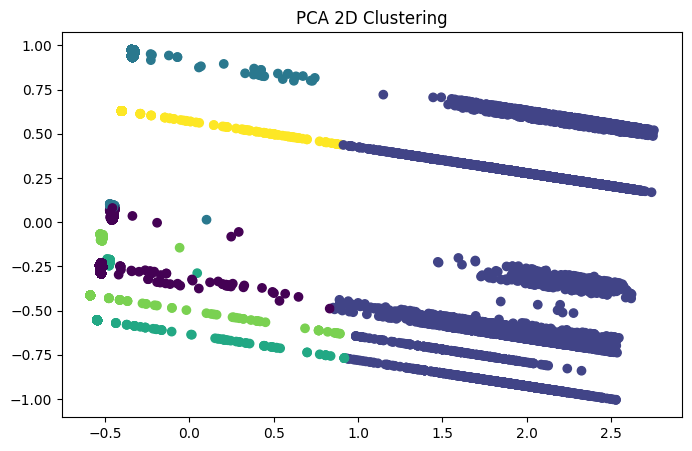

In [115]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_preprocessed)

plt.figure(figsize=(8,5))
plt.scatter(X_pca[:,0],X_pca[:,1], c=cluster_labels)
plt.title('PCA 2D Clustering')
plt.show()

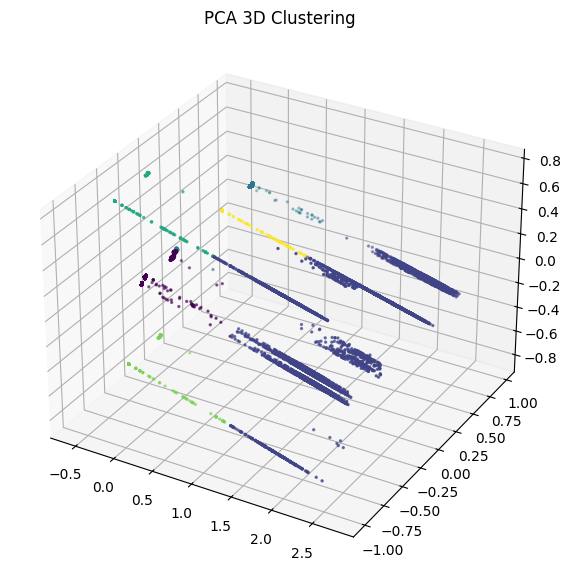

In [116]:
from mpl_toolkits.mplot3d import Axes3D

pca = PCA(n_components=3)
X_pca3= pca.fit_transform(X_preprocessed)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca3[:,0],X_pca3[:,1],X_pca3[:,2], c=cluster_labels, s=2)
plt.title('PCA 3D Clustering')
plt.show()

In [117]:
from google.colab import files
import joblib

joblib.dump(kmeans_pipeline, 'kmeans_clustering.joblib')
files.download('kmeans_clustering.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>